In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r'/content/bank.csv')

In [3]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='object')

In [4]:
df.shape

(8912, 17)

In [5]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [7]:
df.isnull().sum()

,0
age,0
job,7
marital,169
education,27
default,4
balance,13
housing,13
loan,30
contact,31
day,19


In [8]:

num_cols = df.select_dtypes(include="number").columns

for col in num_cols:
    if df[col].isnull().sum() > 0:
        skewness = df[col].skew()

        if -0.5 <= skewness <= 0.5:
            strategy = "mean"
        else:
            strategy = "median"

        from sklearn.impute import SimpleImputer

        imputer = SimpleImputer(strategy=strategy)
        df[[col]] = imputer.fit_transform(df[[col]])

        print(f"{col}: skew={skewness:.2f}, strategy={strategy}")


balance: skew=8.64, strategy=median
day: skew=0.11, strategy=mean
duration: skew=2.14, strategy=median
campaign: skew=5.78, strategy=median
pdays: skew=2.36, strategy=median
previous: skew=7.59, strategy=median


In [9]:

from sklearn.impute import SimpleImputer

cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        imputer = SimpleImputer(strategy="most_frequent")
        df[[col]] = imputer.fit_transform(df[[col]])

        print(f"{col}: missing values imputed with most_frequent")


job: missing values imputed with most_frequent
marital: missing values imputed with most_frequent
education: missing values imputed with most_frequent
default: missing values imputed with most_frequent
housing: missing values imputed with most_frequent
loan: missing values imputed with most_frequent
contact: missing values imputed with most_frequent
month: missing values imputed with most_frequent
deposit: missing values imputed with most_frequent


In [10]:
df.isnull().sum().sum()

np.int64(0)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["deposit"].value_counts()

,count
deposit,
no,4682
yes,4230


In [13]:
df["deposit"].value_counts(normalize=True) * 100

,proportion
deposit,
no,52.535907
yes,47.464093


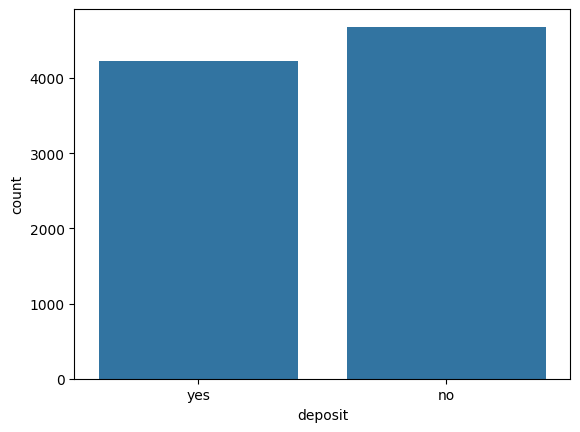

In [14]:
sns.countplot(data=df, x="deposit")
plt.show()

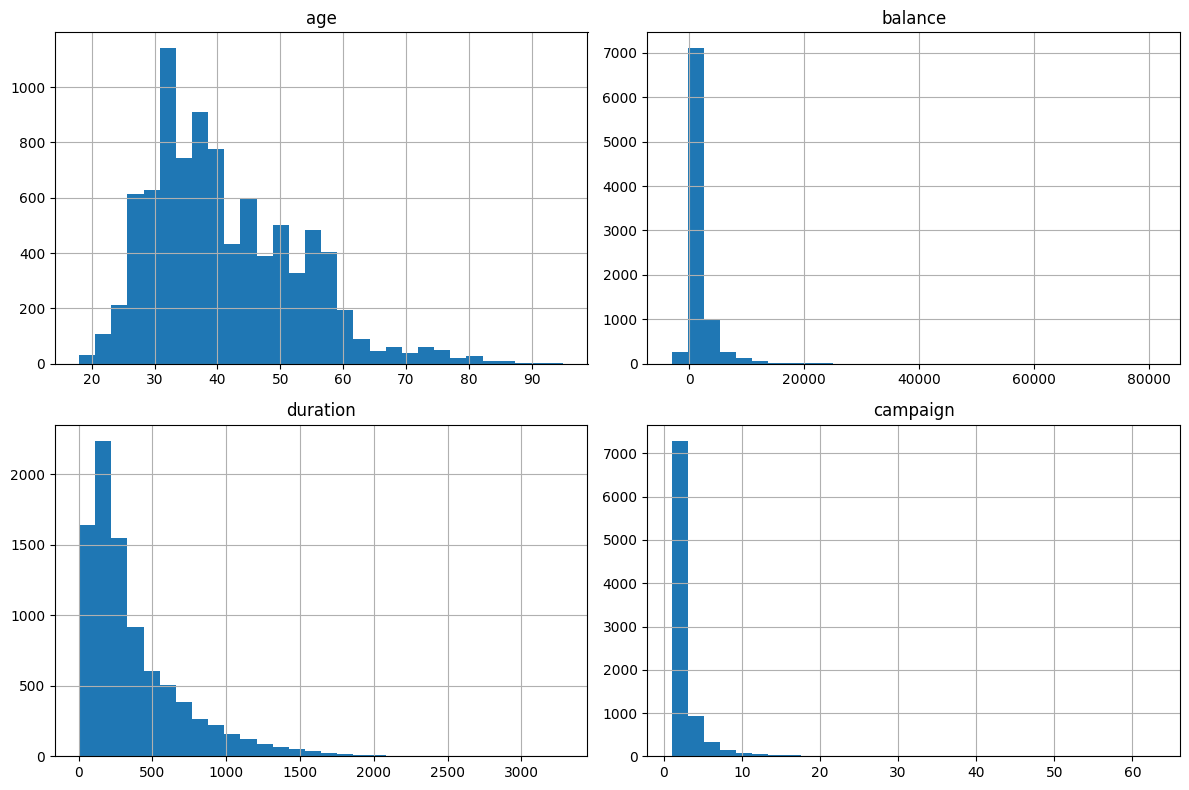

In [15]:
df[["age", "balance", "duration", "campaign"]].hist(
    figsize=(12, 8), bins=30
)
plt.tight_layout()
plt.show()

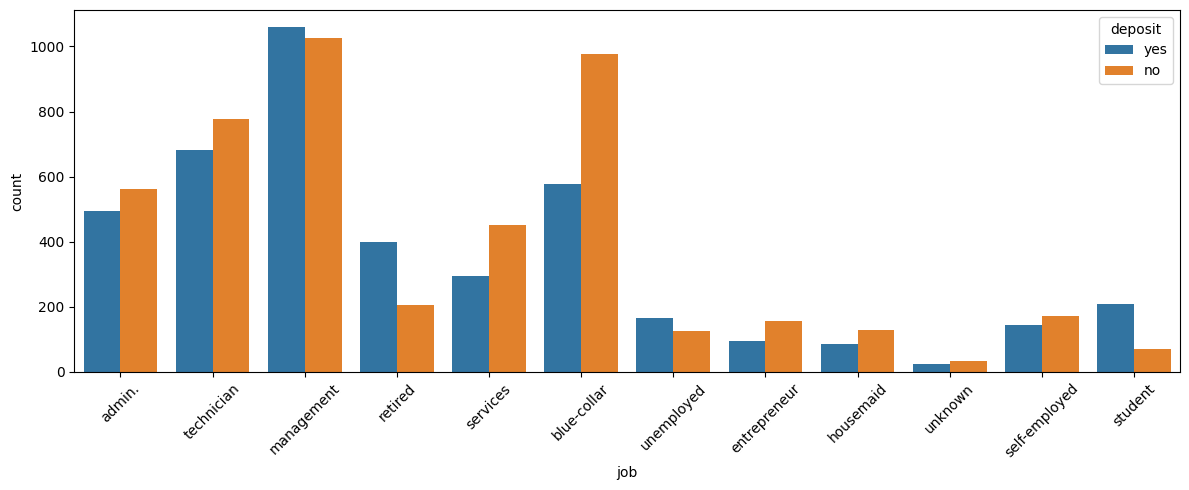

In [16]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="job", hue="deposit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

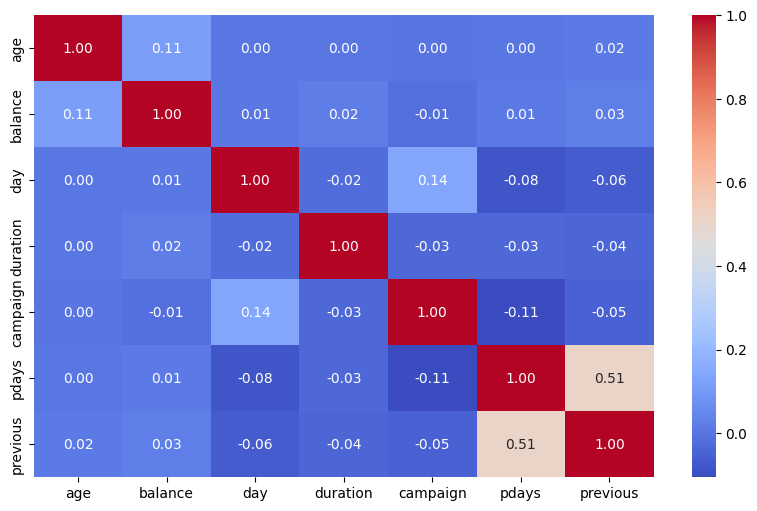

In [17]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.show()


In [18]:
X=df.drop(columns=["deposit"])
y=df["deposit"]

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [20]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns

encoder = OneHotEncoder(handle_unknown="ignore")
X_train_encoded=encoder.fit_transform(X_train[cat_cols])
X_test_encoded=encoder.transform(X_test[cat_cols])

In [21]:

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns


In [22]:

from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(X_train[cat_cols])
X_test_cat = encoder.transform(X_test[cat_cols])

# Convert encoded data to DataFrames
encoded_cols = encoder.get_feature_names_out(cat_cols)

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=encoded_cols,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=encoded_cols,
    index=X_test.index
)

X_train_final = pd.concat(
    [X_train[num_cols], X_train_cat], axis=1
)

X_test_final = pd.concat(
    [X_test[num_cols], X_test_cat], axis=1
)
print("Train shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)



Train shape: (7129, 51)
Test shape: (1783, 51)


In [23]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_final[num_cols] = scaler.fit_transform(
    X_train_final[num_cols]
)

X_test_final[num_cols] = scaler.transform(
    X_test_final[num_cols]
)



In [24]:

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_final, y_train)
y_pred = model.predict(X_test_final)

y_pred,y_test

(array(['no', 'yes', 'no', ..., 'yes', 'yes', 'yes'], dtype=object),
 3868    yes
 151     yes
 8457     no
 4625     no
 2994    yes
        ... 
 4154    yes
 7974     no
 3032    yes
 2960    yes
 6846     no
 Name: deposit, Length: 1783, dtype: object)

In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

pos_label = 'yes'

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=pos_label)
recall = recall_score(y_test, y_pred, pos_label=pos_label)
f1 = f1_score(y_test, y_pred, pos_label=pos_label)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f} (positive class: '{pos_label}')")
print(f"Recall:    {recall:.4f} (positive class: '{pos_label}')")
print(f"F1 Score:  {f1:.4f} (positive class: '{pos_label}')")
print(classification_report(y_test, y_pred))

Accuracy:  0.8149
Precision: 0.8071 (positive class: 'yes')
Recall:    0.8014 (positive class: 'yes')
F1 Score:  0.8043 (positive class: 'yes')
              precision    recall  f1-score   support

          no       0.82      0.83      0.82       937
         yes       0.81      0.80      0.80       846

    accuracy                           0.81      1783
   macro avg       0.81      0.81      0.81      1783
weighted avg       0.81      0.81      0.81      1783



In [26]:
from sklearn.svm import SVC

model = SVC(C= 1, gamma='scale', kernel='rbf')
model.fit(X_train_final, y_train)
y_pred = model.predict(X_test_final)

y_pred,y_test

(array(['no', 'yes', 'no', ..., 'yes', 'yes', 'yes'], dtype=object),
 3868    yes
 151     yes
 8457     no
 4625     no
 2994    yes
        ... 
 4154    yes
 7974     no
 3032    yes
 2960    yes
 6846     no
 Name: deposit, Length: 1783, dtype: object)

In [27]:
from sklearn.metrics import accuracy_score,  confusion_matrix, classification_report

In [28]:
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

          no       0.89      0.82      0.85       937
         yes       0.82      0.89      0.85       846

    accuracy                           0.85      1783
   macro avg       0.85      0.85      0.85      1783
weighted avg       0.86      0.85      0.85      1783



In [29]:
from sklearn.model_selection import GridSearchCV

In [30]:
grid_params = {
    'C': [0.001, 0.01, 0.1 ,1],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}



In [31]:
grid=GridSearchCV(SVC(),grid_params,verbose=3)
grid.fit(X_train_final,y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV 1/5] END C=0.001, gamma=scale, kernel=linear;, score=0.785 total time=   1.5s
[CV 2/5] END C=0.001, gamma=scale, kernel=linear;, score=0.808 total time=   1.5s
[CV 3/5] END C=0.001, gamma=scale, kernel=linear;, score=0.781 total time=   1.5s
[CV 4/5] END C=0.001, gamma=scale, kernel=linear;, score=0.797 total time=   1.5s
[CV 5/5] END C=0.001, gamma=scale, kernel=linear;, score=0.782 total time=   1.4s
[CV 1/5] END ..C=0.001, gamma=scale, kernel=rbf;, score=0.525 total time=   2.9s
[CV 2/5] END ..C=0.001, gamma=scale, kernel=rbf;, score=0.525 total time=   2.9s
[CV 3/5] END ..C=0.001, gamma=scale, kernel=rbf;, score=0.525 total time=   2.9s
[CV 4/5] END ..C=0.001, gamma=scale, kernel=rbf;, score=0.525 total time=   3.0s
[CV 5/5] END ..C=0.001, gamma=scale, kernel=rbf;, score=0.526 total time=   3.1s
[CV 1/5] END C=0.001, gamma=auto, kernel=linear;, score=0.785 total time=   1.4s
[CV 2/5] END C=0.001, gamma=auto, kernel=li

GridSearchCV(estimator=SVC(),
             param_grid={'C': [0.001, 0.01, 0.1, 1], 'gamma': ['scale', 'auto'],
                         'kernel': ['linear', 'rbf']},
             verbose=3)

In [32]:
print(grid.best_params_)

{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}


In [33]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train_final, y_train)

y_pred = model.predict(X_test_final)



In [34]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          no       0.78      0.79      0.79       937
         yes       0.77      0.76      0.76       846

    accuracy                           0.78      1783
   macro avg       0.77      0.77      0.77      1783
weighted avg       0.78      0.78      0.78      1783



In [35]:
from sklearn.model_selection import GridSearchCV




In [36]:
grid_params = {
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [3,4,5,9]
}

In [37]:
grid=GridSearchCV(DecisionTreeClassifier(random_state=42),grid_params,verbose=3,)
grid.fit(X_train_final,y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
[CV 1/5] END max_depth=None, min_samples_leaf=3, min_samples_split=2;, score=0.792 total time=   0.1s
[CV 2/5] END max_depth=None, min_samples_leaf=3, min_samples_split=2;, score=0.806 total time=   0.1s
[CV 3/5] END max_depth=None, min_samples_leaf=3, min_samples_split=2;, score=0.783 total time=   0.1s
[CV 4/5] END max_depth=None, min_samples_leaf=3, min_samples_split=2;, score=0.785 total time=   0.1s
[CV 5/5] END max_depth=None, min_samples_leaf=3, min_samples_split=2;, score=0.778 total time=   0.1s
[CV 1/5] END max_depth=None, min_samples_leaf=3, min_samples_split=5;, score=0.792 total time=   0.1s
[CV 2/5] END max_depth=None, min_samples_leaf=3, min_samples_split=5;, score=0.806 total time=   0.1s
[CV 3/5] END max_depth=None, min_samples_leaf=3, min_samples_split=5;, score=0.783 total time=   0.1s
[CV 4/5] END max_depth=None, min_samples_leaf=3, min_samples_split=5;, score=0.785 total time=   0.1s
[CV 5/5] END max_dep

GridSearchCV(estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [3, 4, 5, 9],
                         'min_samples_split': [2, 5, 10]},
             verbose=3)

In [38]:
print(grid.best_params_)

{'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}


In [39]:
print(grid.best_score_)

0.8113325951625207


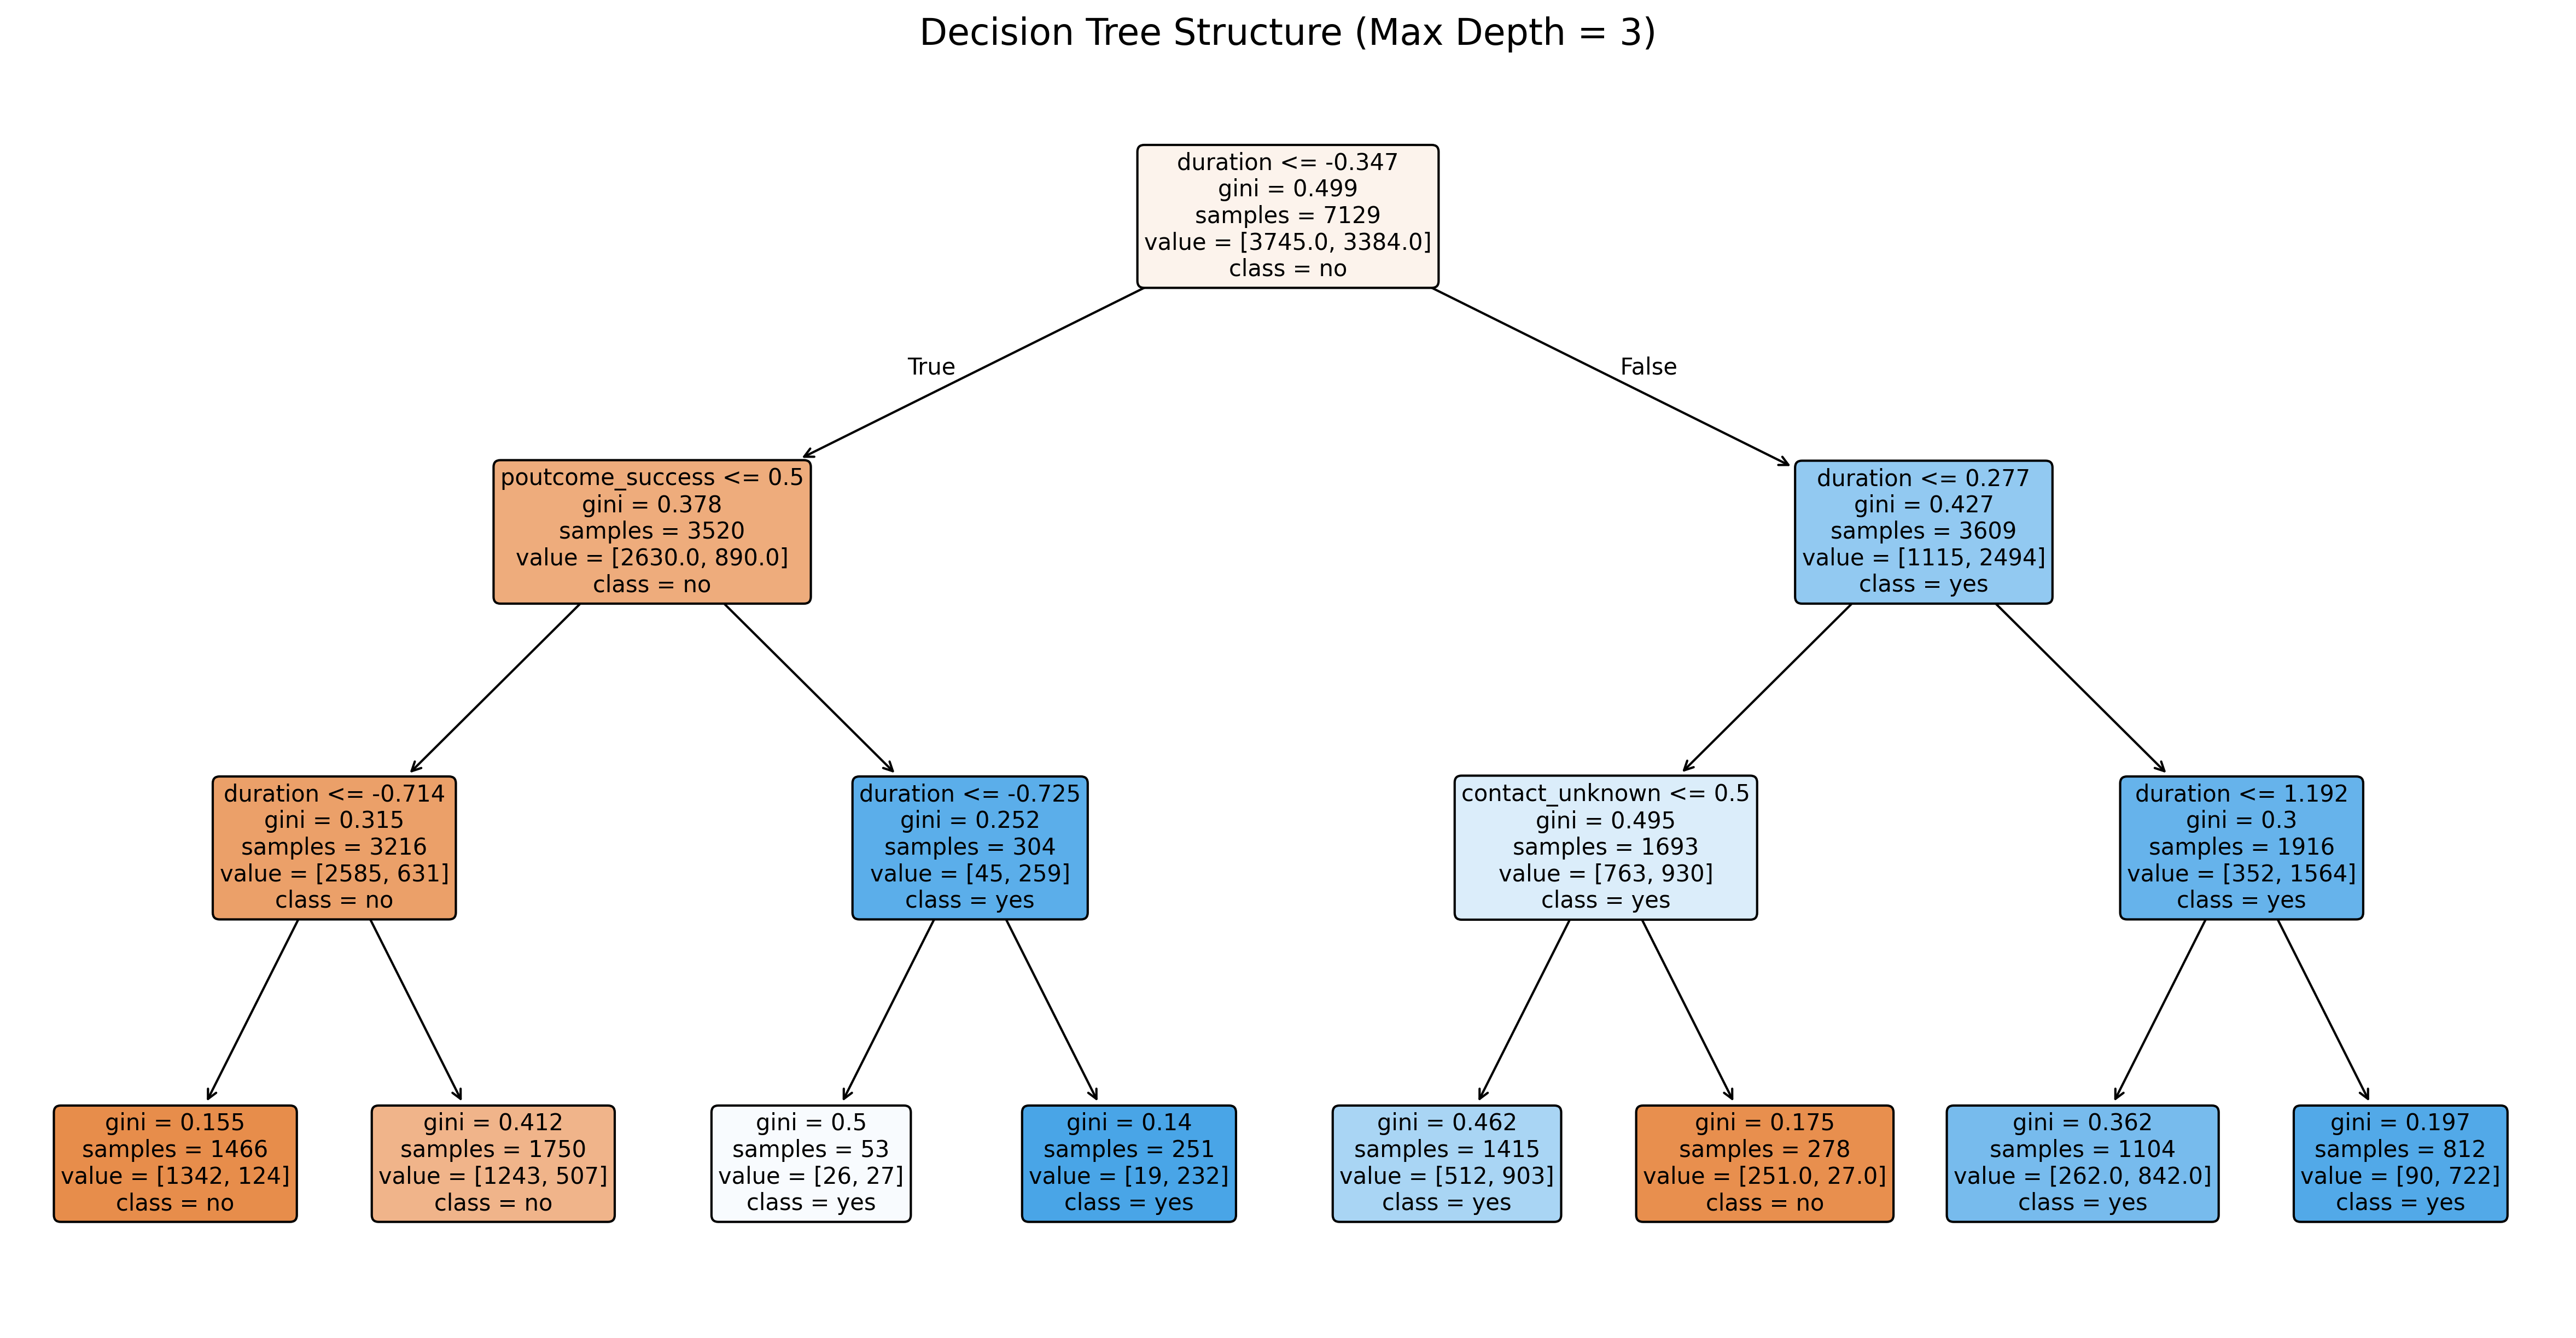

In [40]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, DecisionTreeClassifier

best_model = DecisionTreeClassifier(
    max_depth=3,  # حددنا العمق بـ 3 لتسهيل قراءة الرسم وتجنب التداخل
    min_samples_leaf=5,
    min_samples_split=2,
    random_state=42
)
best_model.fit(X_train_final, y_train)

plt.figure(figsize=(20, 10), dpi=300)
plot_tree(
    best_model,
    feature_names=X_train_final.columns.tolist(),
    class_names=best_model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure (Max Depth = 3)", fontsize=16)
plt.show()

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1. Fit an initial model on all features to get importances
initial_model = RandomForestClassifier(random_state=42)
initial_model.fit(X_train_final, y_train)

importances = pd.Series(
    initial_model.feature_importances_,
    index=X_train_final.columns
)

# 2. Select the top 5 features
selected_columns = importances.sort_values(ascending=False).head(5).index
print("Selected Columns:", selected_columns.tolist())

# 3. Filter training and testing sets
X_train_selected = X_train_final[selected_columns]
X_test_selected = X_test_final[selected_columns]

# 4. Train a new model on ONLY the selected features
final_rf_model = RandomForestClassifier(random_state=42)
final_rf_model.fit(X_train_selected, y_train)

# 5. Predict and evaluate
y_pred = final_rf_model.predict(X_test_selected)
print(classification_report(y_test, y_pred))

Selected Columns: ['duration', 'balance', 'age', 'day', 'campaign']
              precision    recall  f1-score   support

          no       0.78      0.75      0.77       937
         yes       0.74      0.76      0.75       846

    accuracy                           0.76      1783
   macro avg       0.76      0.76      0.76      1783
weighted avg       0.76      0.76      0.76      1783



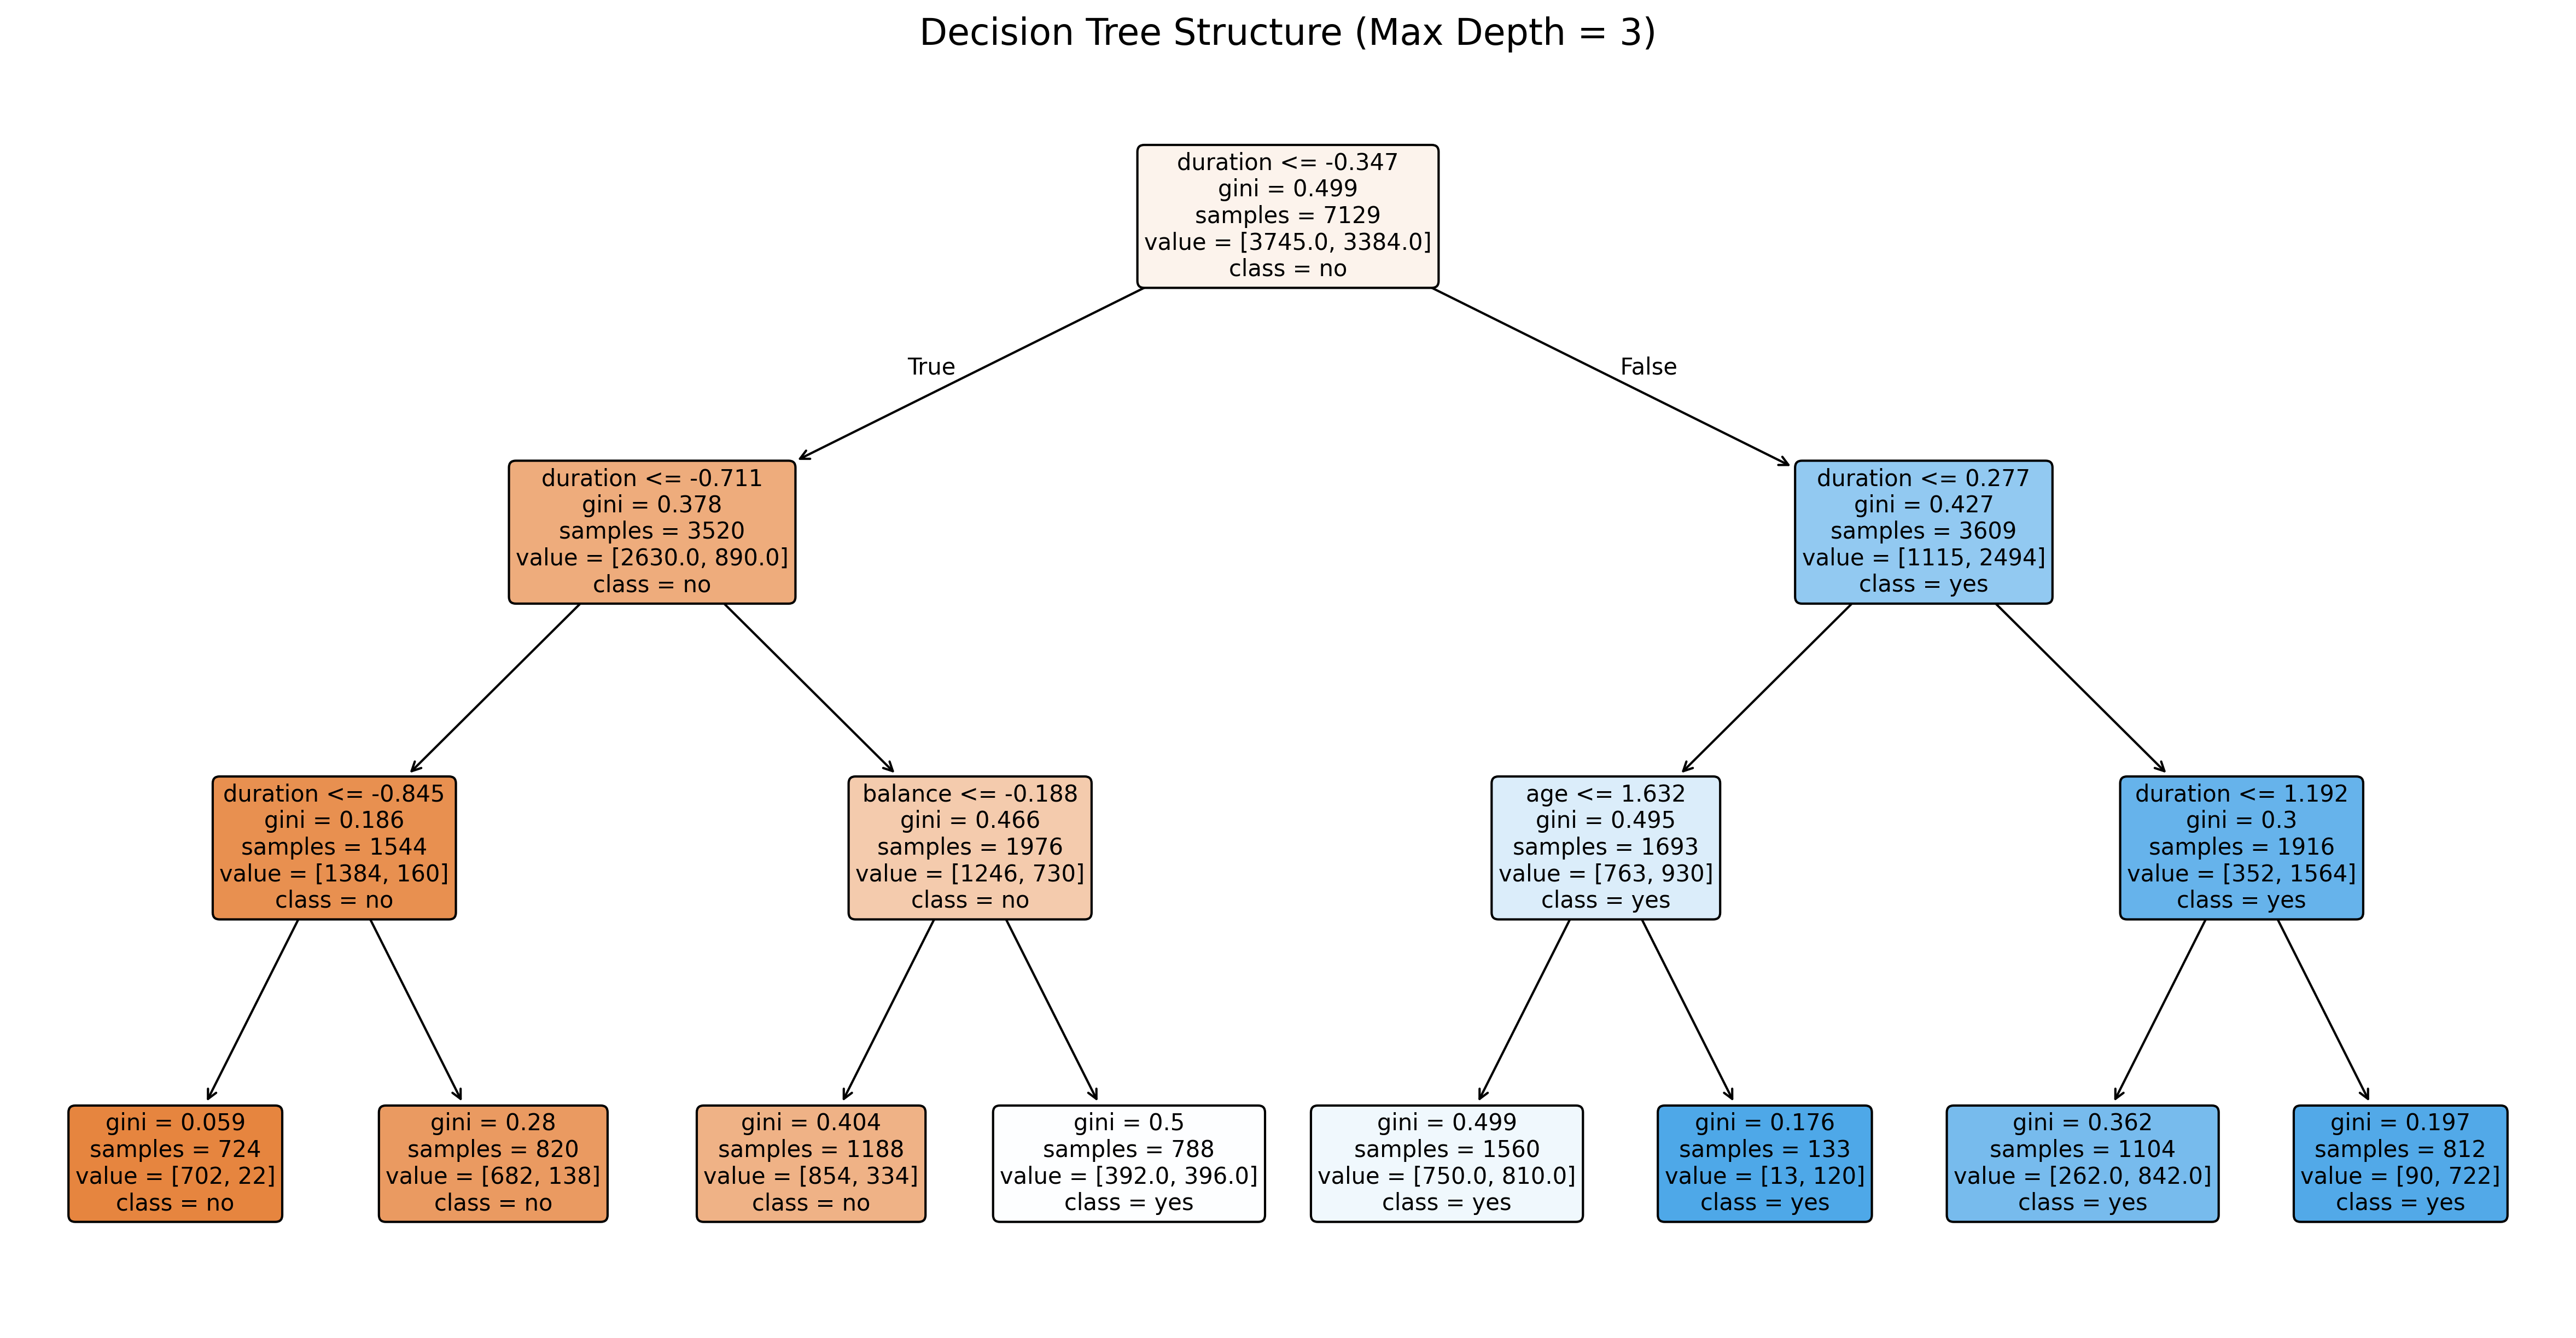

In [43]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, DecisionTreeClassifier

best_model = DecisionTreeClassifier(
    max_depth=3,  # حددنا العمق بـ 3 لتسهيل قراءة الرسم وتجنب التداخل
    min_samples_leaf=5,
    min_samples_split=2,
    random_state=42
)
best_model.fit(X_train_final, y_train)

plt.figure(figsize=(20, 10), dpi=300)
plot_tree(
    best_model,
    feature_names=X_train_final.columns.tolist(),
    class_names=best_model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure (Max Depth = 3)", fontsize=16)
plt.show()

In [46]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 51.6 MB/s  0:00:01


In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from tqdm import tqdm

In [48]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


[Logistic Regression] Confusion Matrix:
 [[785 152]
 [334 512]]


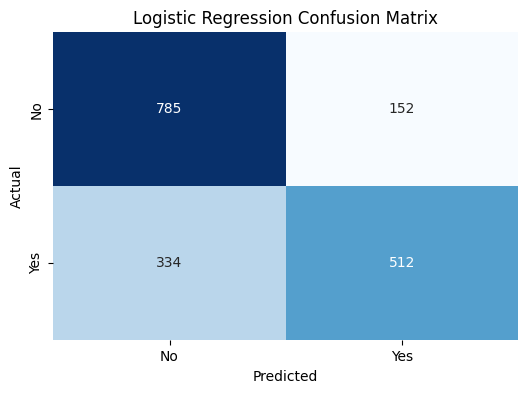


[Logistic Regression] Classification Report:

              precision    recall  f1-score   support

          No       0.70      0.84      0.76       937
         Yes       0.77      0.61      0.68       846

    accuracy                           0.73      1783
   macro avg       0.74      0.72      0.72      1783
weighted avg       0.73      0.73      0.72      1783

ROC-AUC: 0.8185547658514801


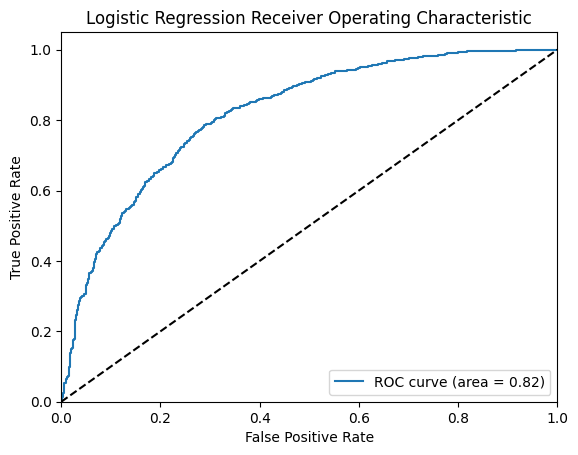

PR AUC: 0.7753737532815528


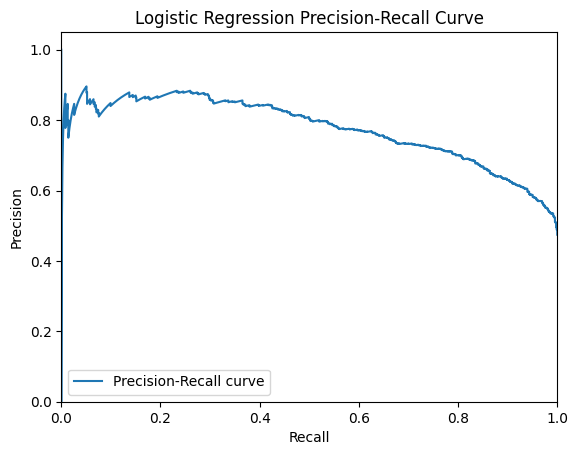

  8%|▊         | 1/13 [00:01<00:13,  1.11s/it]


[KNN] Confusion Matrix:
 [[687 250]
 [265 581]]


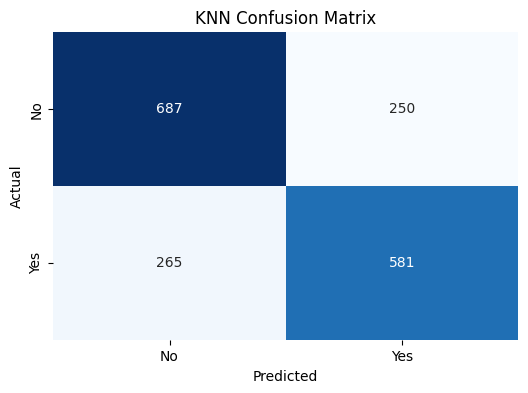


[KNN] Classification Report:

              precision    recall  f1-score   support

          No       0.72      0.73      0.73       937
         Yes       0.70      0.69      0.69       846

    accuracy                           0.71      1783
   macro avg       0.71      0.71      0.71      1783
weighted avg       0.71      0.71      0.71      1783

ROC-AUC: 0.7797930369798487


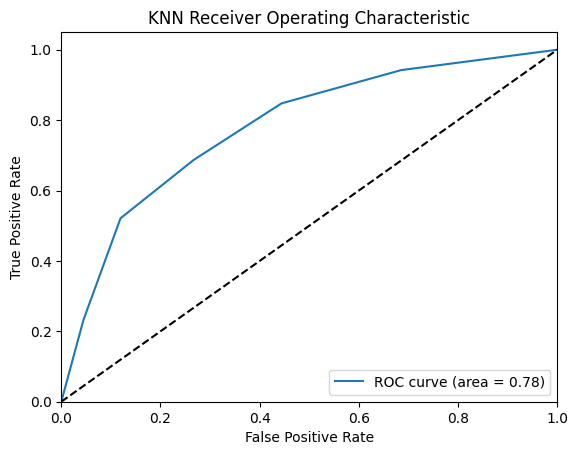

PR AUC: 0.7192299547341541


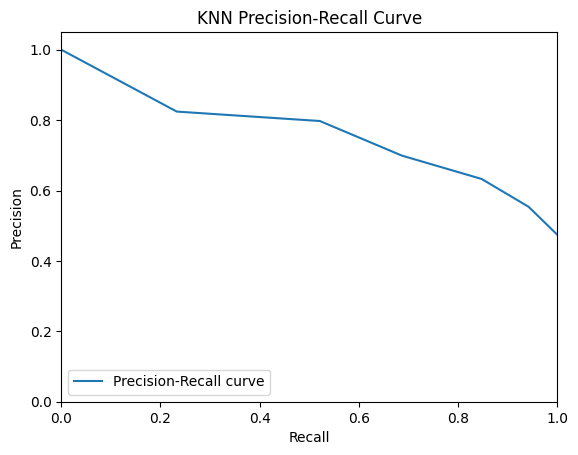

 15%|█▌        | 2/13 [00:02<00:12,  1.13s/it]


[SVC] Confusion Matrix:
 [[717 220]
 [214 632]]


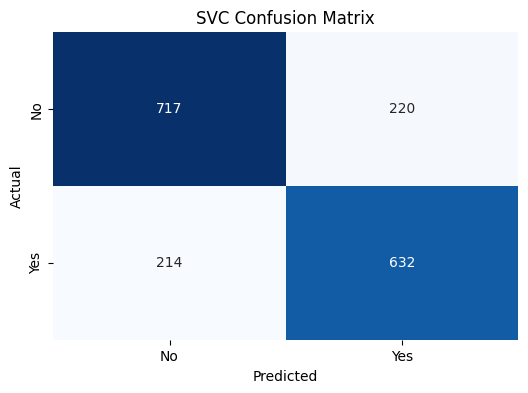


[SVC] Classification Report:

              precision    recall  f1-score   support

          No       0.77      0.77      0.77       937
         Yes       0.74      0.75      0.74       846

    accuracy                           0.76      1783
   macro avg       0.76      0.76      0.76      1783
weighted avg       0.76      0.76      0.76      1783

ROC-AUC: 0.8297670499128299


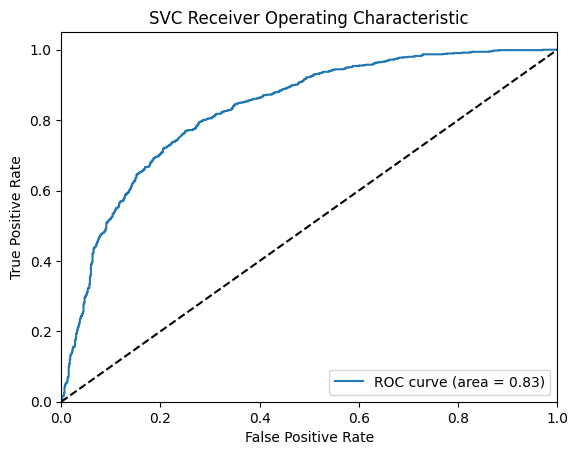

PR AUC: 0.7820083647482485


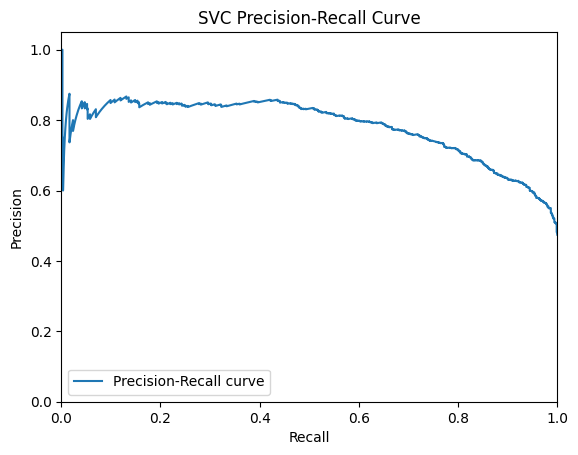

 23%|██▎       | 3/13 [00:11<00:48,  4.82s/it]


[Decision Tree] Confusion Matrix:
 [[627 310]
 [281 565]]


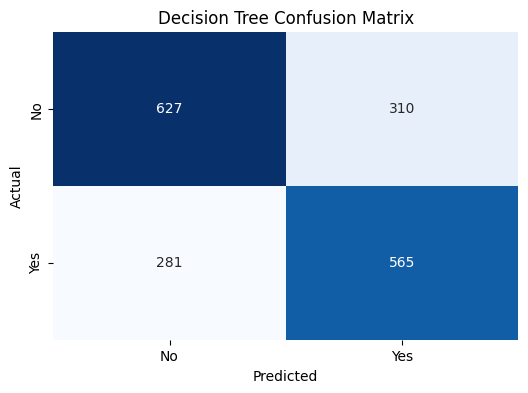


[Decision Tree] Classification Report:

              precision    recall  f1-score   support

          No       0.69      0.67      0.68       937
         Yes       0.65      0.67      0.66       846

    accuracy                           0.67      1783
   macro avg       0.67      0.67      0.67      1783
weighted avg       0.67      0.67      0.67      1783

ROC-AUC: 0.6685027917174423


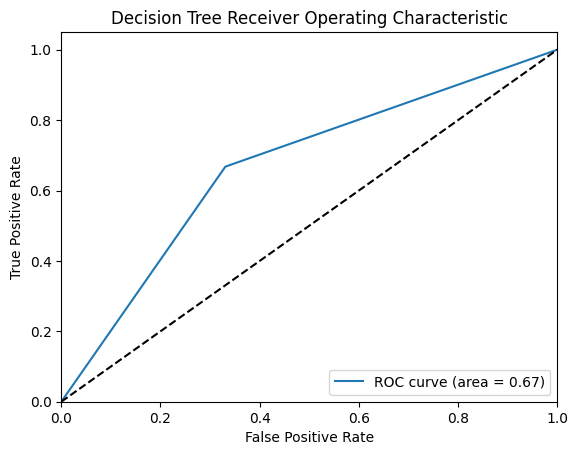

PR AUC: 0.5888389974510665


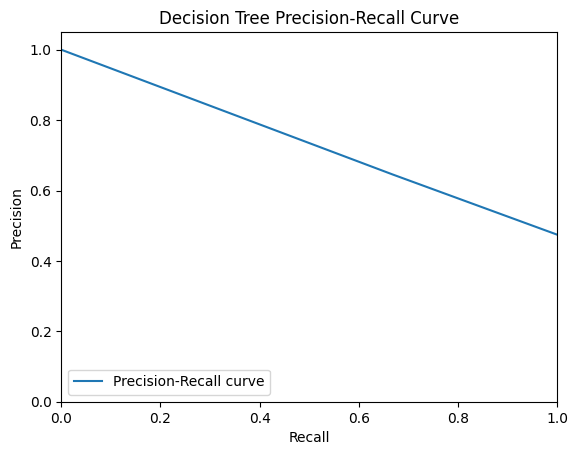

 31%|███       | 4/13 [00:12<00:28,  3.15s/it]


[Naive Bayes] Confusion Matrix:
 [[813 124]
 [362 484]]


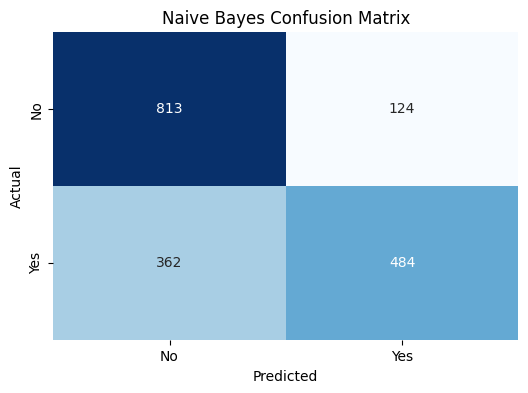


[Naive Bayes] Classification Report:

              precision    recall  f1-score   support

          No       0.69      0.87      0.77       937
         Yes       0.80      0.57      0.67       846

    accuracy                           0.73      1783
   macro avg       0.74      0.72      0.72      1783
weighted avg       0.74      0.73      0.72      1783

ROC-AUC: 0.7896025240254219


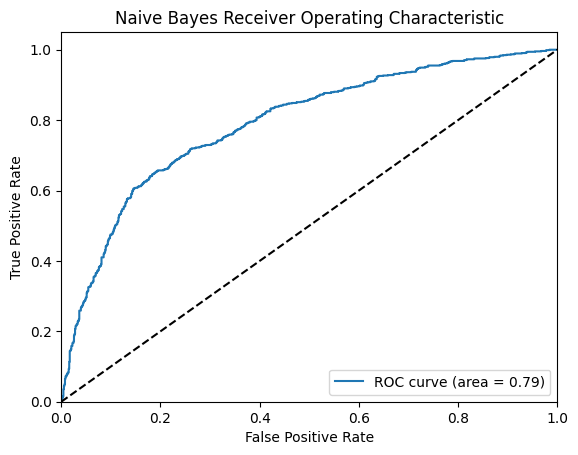

PR AUC: 0.7598240691182814


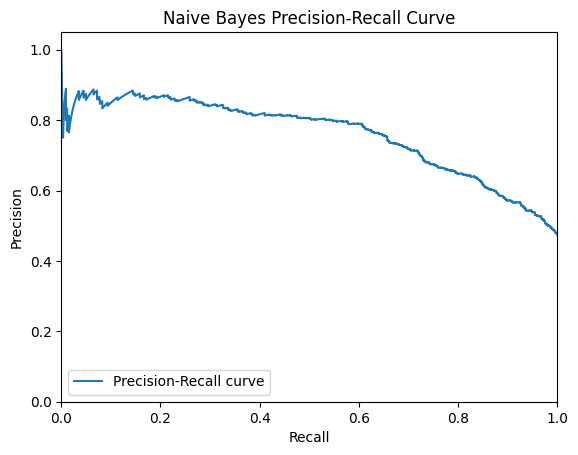

 38%|███▊      | 5/13 [00:12<00:17,  2.20s/it]


[Random Forest] Confusion Matrix:
 [[710 227]
 [208 638]]


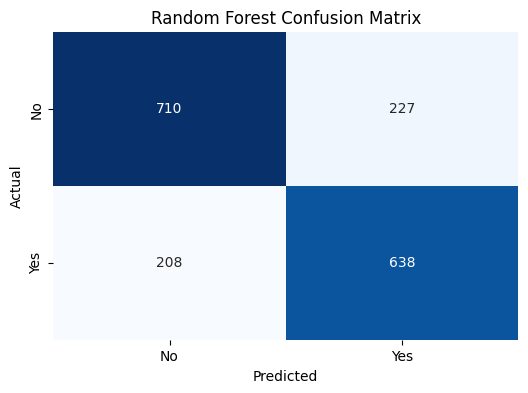


[Random Forest] Classification Report:

              precision    recall  f1-score   support

          No       0.77      0.76      0.77       937
         Yes       0.74      0.75      0.75       846

    accuracy                           0.76      1783
   macro avg       0.76      0.76      0.76      1783
weighted avg       0.76      0.76      0.76      1783

ROC-AUC: 0.833557881776506


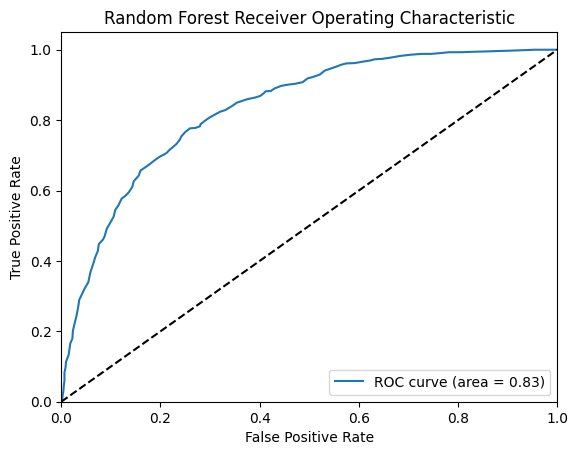

PR AUC: 0.7942214239859139


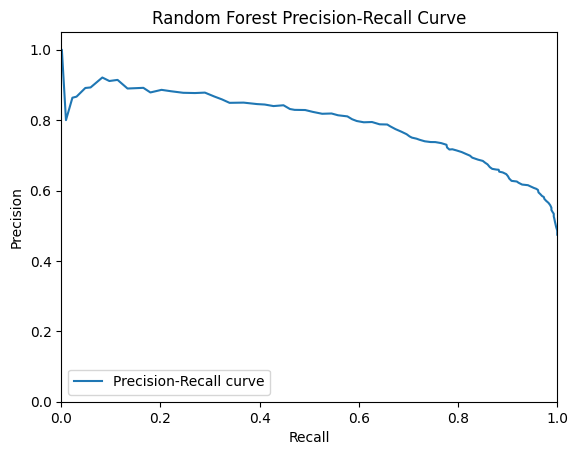

 46%|████▌     | 6/13 [00:14<00:14,  2.13s/it]


[Extra Trees] Confusion Matrix:
 [[711 226]
 [208 638]]


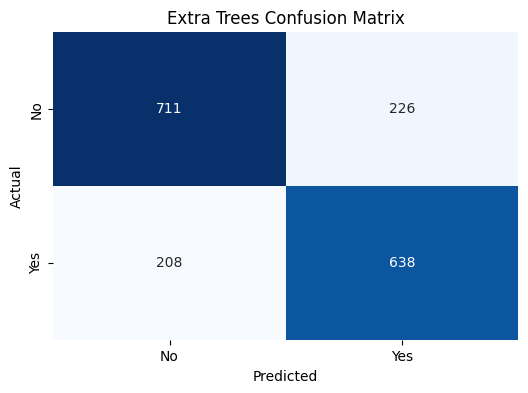


[Extra Trees] Classification Report:

              precision    recall  f1-score   support

          No       0.77      0.76      0.77       937
         Yes       0.74      0.75      0.75       846

    accuracy                           0.76      1783
   macro avg       0.76      0.76      0.76      1783
weighted avg       0.76      0.76      0.76      1783

ROC-AUC: 0.8297922800749841


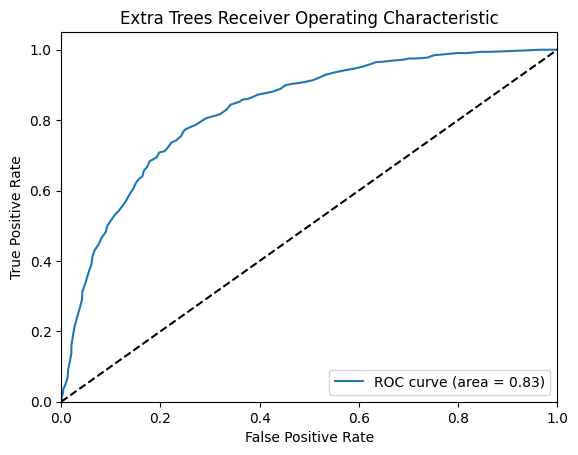

PR AUC: 0.787627505686987


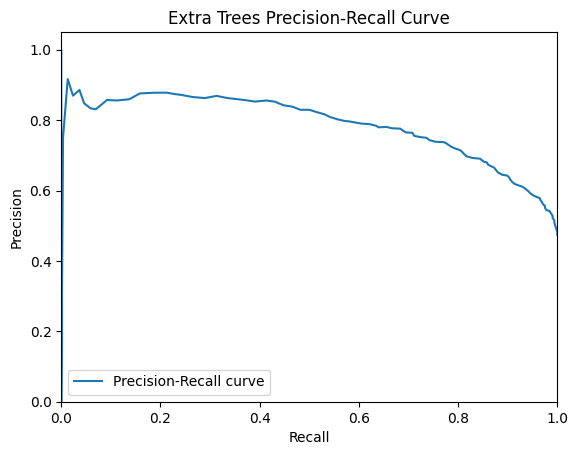

 54%|█████▍    | 7/13 [00:16<00:11,  1.93s/it]


[AdaBoost] Confusion Matrix:
 [[674 263]
 [211 635]]


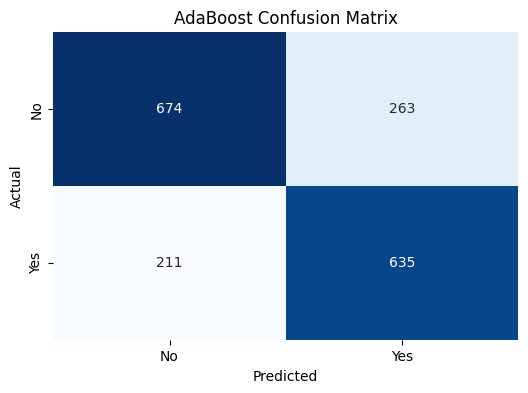


[AdaBoost] Classification Report:

              precision    recall  f1-score   support

          No       0.76      0.72      0.74       937
         Yes       0.71      0.75      0.73       846

    accuracy                           0.73      1783
   macro avg       0.73      0.73      0.73      1783
weighted avg       0.74      0.73      0.73      1783

ROC-AUC: 0.8271525743595954


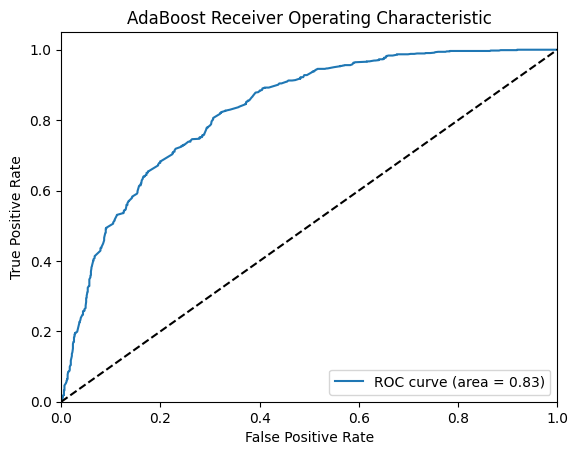

PR AUC: 0.7754492540000721


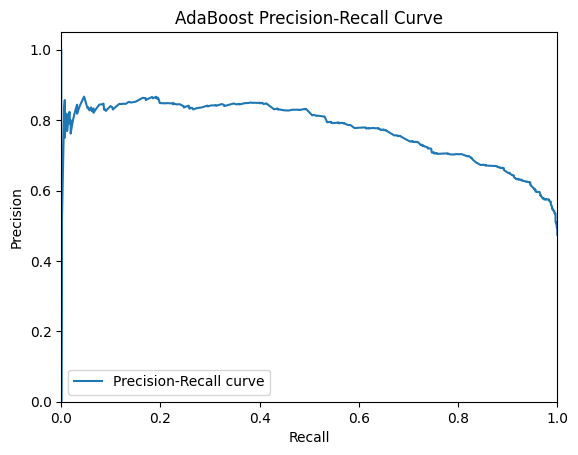

 62%|██████▏   | 8/13 [00:17<00:08,  1.68s/it]


[Gradient Boosting] Confusion Matrix:
 [[724 213]
 [187 659]]


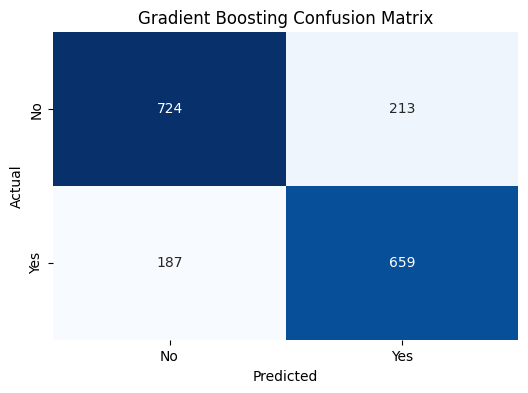


[Gradient Boosting] Classification Report:

              precision    recall  f1-score   support

          No       0.79      0.77      0.78       937
         Yes       0.76      0.78      0.77       846

    accuracy                           0.78      1783
   macro avg       0.78      0.78      0.78      1783
weighted avg       0.78      0.78      0.78      1783

ROC-AUC: 0.8485792895690941


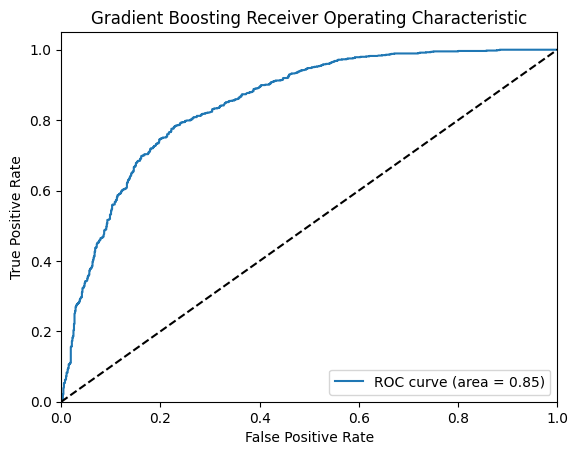

PR AUC: 0.8019540933113263


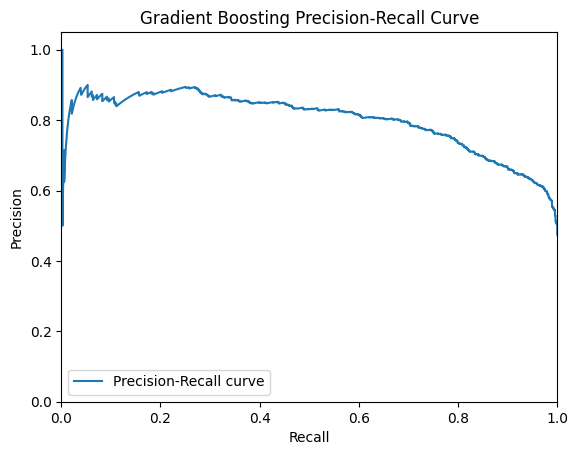

 69%|██████▉   | 9/13 [00:18<00:06,  1.62s/it]


[Hist Gradient Boosting] Confusion Matrix:
 [[713 224]
 [182 664]]


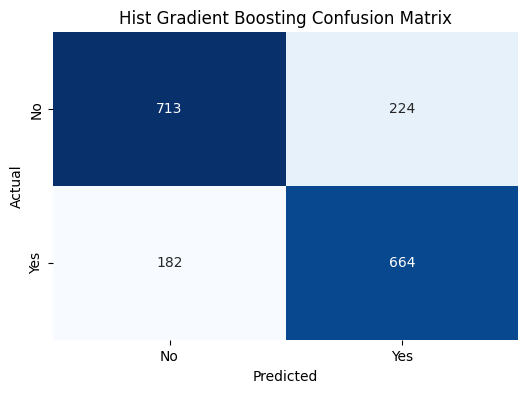


[Hist Gradient Boosting] Classification Report:

              precision    recall  f1-score   support

          No       0.80      0.76      0.78       937
         Yes       0.75      0.78      0.77       846

    accuracy                           0.77      1783
   macro avg       0.77      0.77      0.77      1783
weighted avg       0.77      0.77      0.77      1783

ROC-AUC: 0.8467204573723796


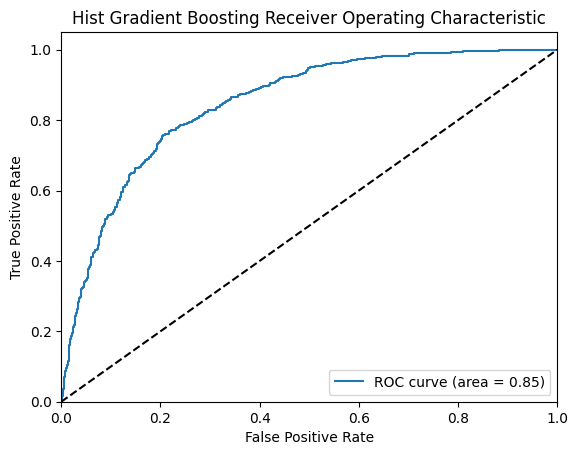

PR AUC: 0.8075190108873924


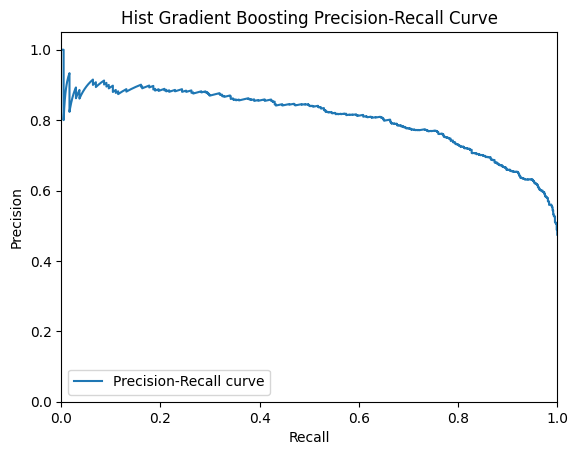

 77%|███████▋  | 10/13 [00:19<00:05,  1.96s/it]


ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1], got ['no' 'yes']

In [53]:
results = {}

for name, model in tqdm(models.items()):
    # Use the processed, encoded, and scaled datasets
    model.fit(X_train_final, y_train)

    train_pred = model.predict(X_train_final)
    test_pred  = model.predict(X_test_final)

    cm = confusion_matrix(y_test, test_pred)
    print(f"\n[{name}] Confusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title(f'{name} Confusion Matrix')
    plt.show()

    print(f"\n[{name}] Classification Report:\n")
    print(classification_report(y_test, test_pred, target_names=['No', 'Yes'], zero_division=0))

    y_pred_prob = model.predict_proba(X_test_final)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve (explicitly passing pos_label='yes')
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label='yes')
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{name} Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    # PR AUC (explicitly passing pos_label='yes')
    pr_auc = average_precision_score(y_test, y_pred_prob, pos_label='yes')
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob, pos_label='yes')
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'{name} Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred, pos_label='yes'),
        "Test Precision": precision_score(y_test, test_pred, pos_label='yes'),
        "Train Recall": recall_score(y_train, train_pred, pos_label='yes'),
        "Test Recall": recall_score(y_test, test_pred, pos_label='yes'),
        "Train F1 Score": f1_score(y_train, train_pred, pos_label='yes'),
        "Test F1 Score": f1_score(y_test, test_pred, pos_label='yes'),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc
    }

# **voting**

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:16:38] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[766 171]
 [235 611]]


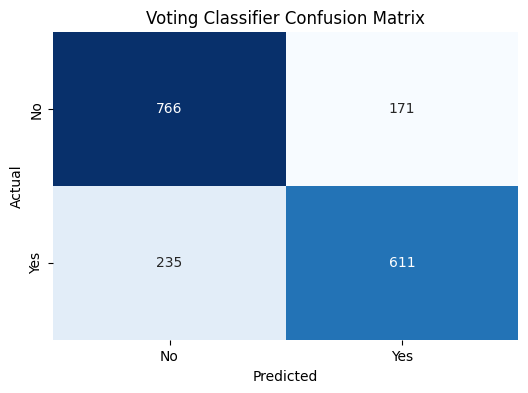


Classification Report:

              precision    recall  f1-score   support

          No       0.77      0.82      0.79       937
         Yes       0.78      0.72      0.75       846

    accuracy                           0.77      1783
   macro avg       0.77      0.77      0.77      1783
weighted avg       0.77      0.77      0.77      1783

ROC-AUC: 0.8422610262116155


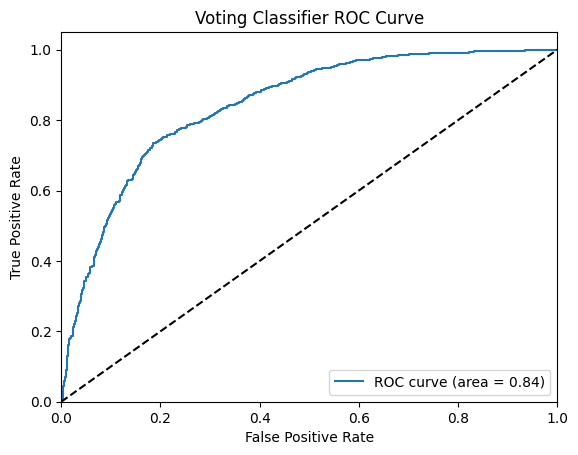

PR AUC: 0.8011108835133544


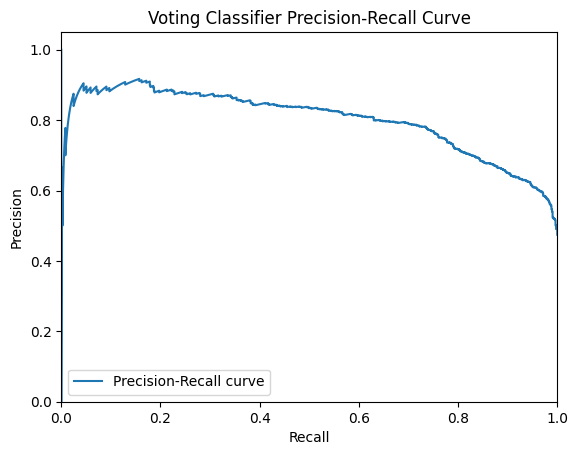

In [55]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft"
)

# Train the VotingClassifier on the processed numeric data
voting_model.fit(X_train_final, y_train)
voting_train_pred = voting_model.predict(X_train_final)
voting_test_pred = voting_model.predict(X_test_final)

# Plot Confusion Matrix
cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Voting Classifier Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred, target_names=['No', 'Yes'], zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test_final)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label='yes')
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Voting Classifier ROC Curve')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob, pos_label='yes')
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob, pos_label='yes')
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Voting Classifier Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

# Store results securely
results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred, pos_label='yes'),
    "Test Precision": precision_score(y_test, voting_test_pred, pos_label='yes'),
    "Train Recall": recall_score(y_train, voting_train_pred, pos_label='yes'),
    "Test Recall": recall_score(y_test, voting_test_pred, pos_label='yes'),
    "Train F1 Score": f1_score(y_train, voting_train_pred, pos_label='yes'),
    "Test F1 Score": f1_score(y_test, voting_test_pred, pos_label='yes'),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

## stacking

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [13:20:32] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter", "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[695 242]
 [212 634]]


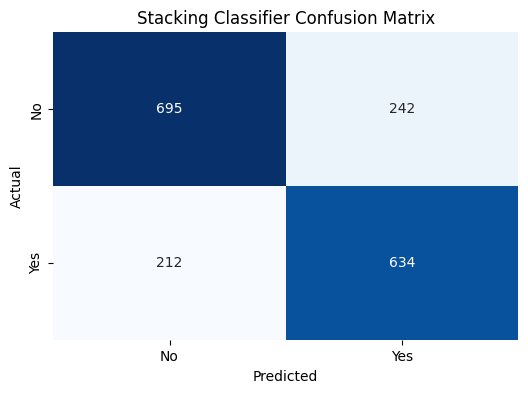


Classification Report:

              precision    recall  f1-score   support

          No       0.77      0.74      0.75       937
         Yes       0.72      0.75      0.74       846

    accuracy                           0.75      1783
   macro avg       0.75      0.75      0.75      1783
weighted avg       0.75      0.75      0.75      1783

ROC-AUC: 0.8136765139989556


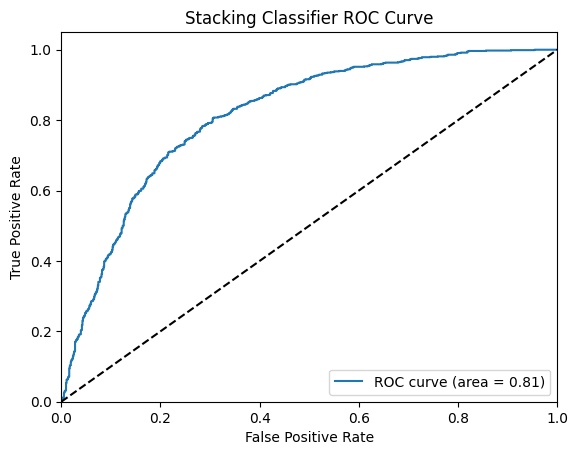

PR AUC: 0.7568041951683172


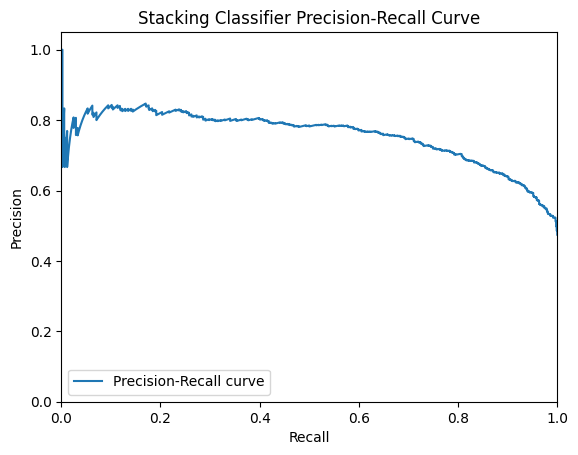

In [57]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),
    ],
    final_estimator=XGBClassifier(max_iter=2000, eval_metric='logloss', use_label_encoder=False, random_state=1),
    stack_method="predict_proba",
    n_jobs=-1
)

# Train using processed numeric data
stack_auto.fit(X_train_final, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train_final)
stack_auto_test_pred  = stack_auto.predict(X_test_final)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Stacking Classifier Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred, target_names=['No', 'Yes'], zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test_final)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label='yes')
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Stacking Classifier ROC Curve')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob, pos_label='yes')
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob, pos_label='yes')
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Stacking Classifier Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred, pos_label='yes'),
    "Test Precision": precision_score(y_test, stack_auto_test_pred, pos_label='yes'),
    "Train Recall": recall_score(y_train, stack_auto_train_pred, pos_label='yes'),
    "Test Recall": recall_score(y_test, stack_auto_test_pred, pos_label='yes'),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred, pos_label='yes'),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred, pos_label='yes'),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [58]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [59]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Gradient Boosting,0.784963,0.775659,0.770061,0.755734,0.779846,0.778960,0.774923,0.767171,0.784716,0.775819,0.848579,0.801954
Hist Gradient Boosting,0.839248,0.772294,0.814679,0.747748,0.856087,0.784870,0.834870,0.765859,0.840060,0.772905,0.846720,0.807519
Voting Classifier,0.893954,0.772294,0.898665,0.781330,0.875296,0.722222,0.886826,0.750614,0.893055,0.769862,0.842261,0.801111
Extra Trees,1.000000,0.756590,1.000000,0.738426,1.000000,0.754137,1.000000,0.746199,1.000000,0.756471,0.829792,0.787628
Random Forest,1.000000,0.756029,1.000000,0.737572,1.000000,0.754137,1.000000,0.745763,1.000000,0.755937,0.833558,0.794221
SVC,0.762519,0.756590,0.752162,0.741784,0.745272,0.747045,0.748701,0.744405,0.761688,0.756127,0.829767,0.782008
Stacking Classifier,0.813859,0.745373,0.802946,0.723744,0.805556,0.749409,0.804248,0.736353,0.813459,0.745569,0.813677,0.756804
AdaBoost,0.748773,0.734156,0.733099,0.707127,0.740248,0.750591,0.736656,0.728211,0.748362,0.734954,0.827153,0.775449
KNN,0.816664,0.711161,0.807704,0.699158,0.805556,0.686761,0.806628,0.692904,0.816129,0.709976,0.779793,0.719230
Logistic Regression,0.721139,0.727426,0.761423,0.771084,0.600768,0.605201,0.671622,0.678146,0.715337,0.721491,0.818555,0.775374


<Axes: >

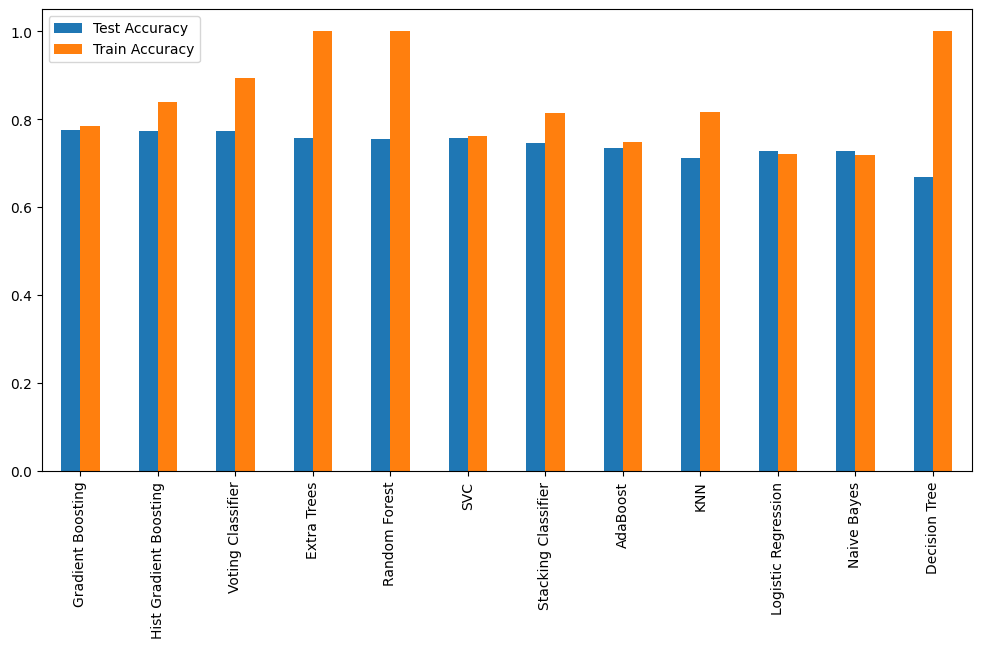

In [60]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

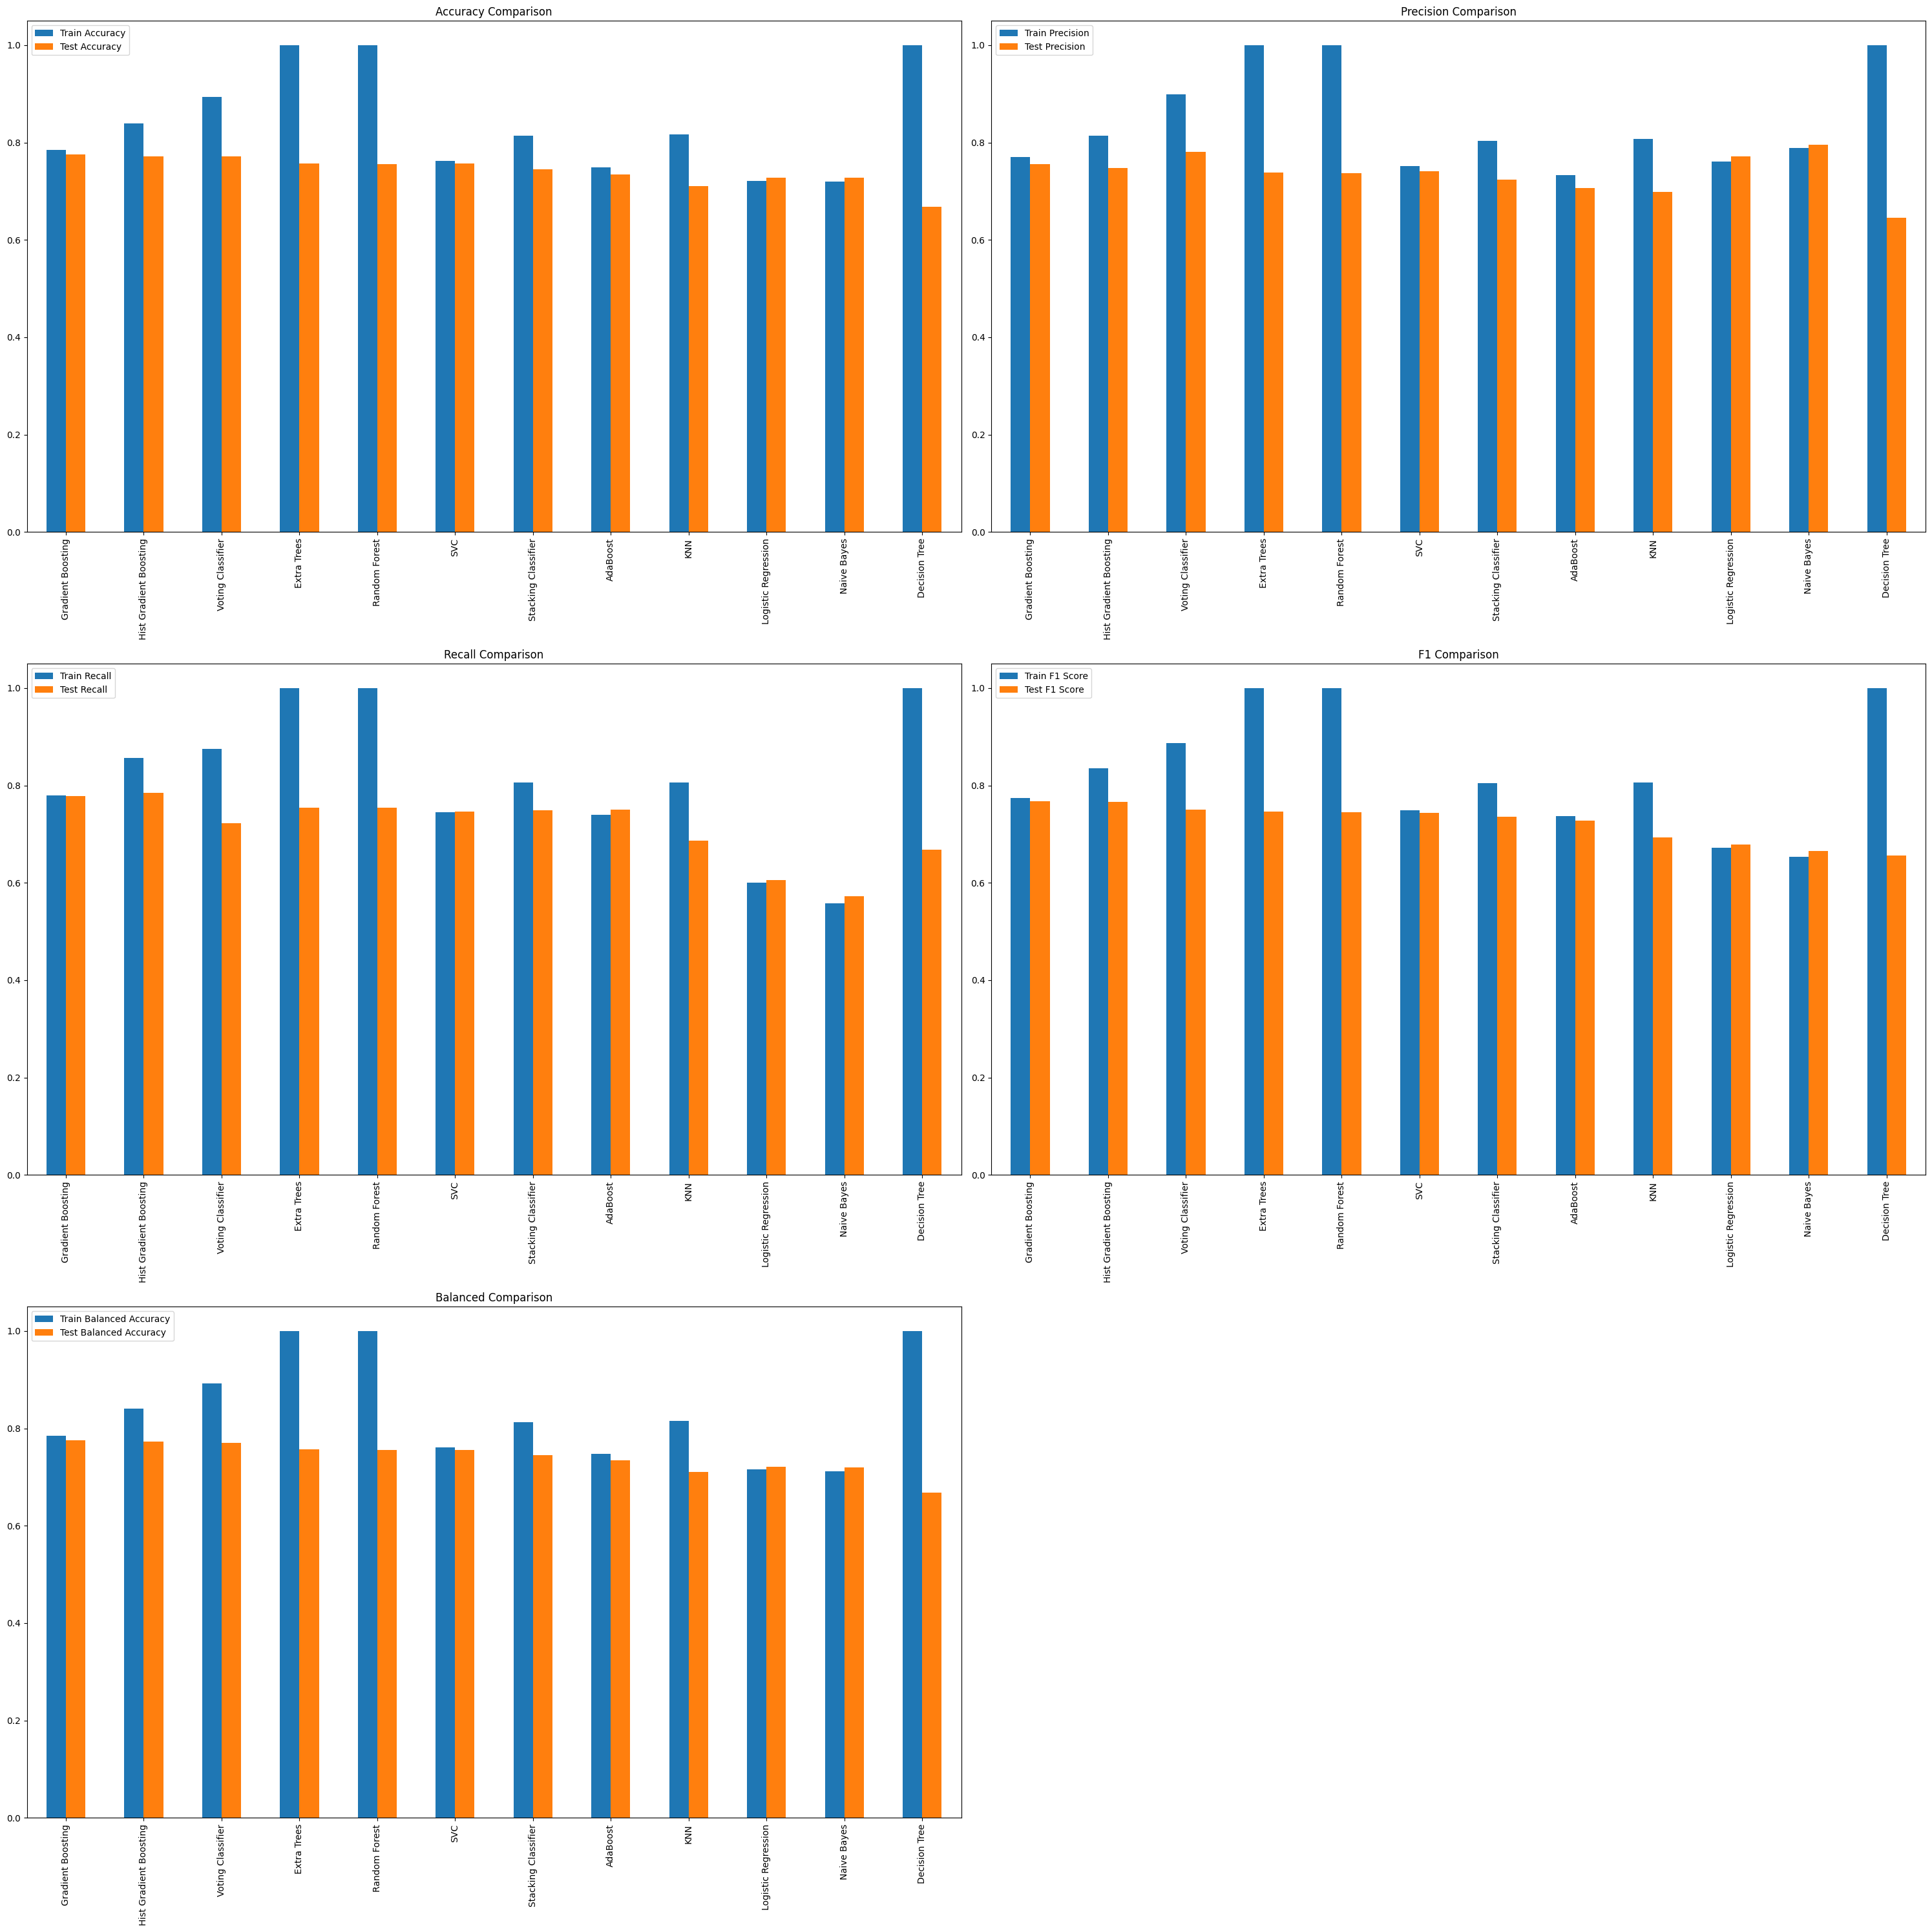

In [61]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()